# ResNet-56 na CIFAR-10

Notatnik zawiera:
1. wyjaśnienie koncepcji uczenia rezydualnego (*residual learning*) oraz architektury sieci ResNet-56 w dwóch wariantach dopasowania wymiarów skrótu (Opcja A oraz Opcja B),
2. implementację obu wariantów połączeń skrótowych, bloku rezydualnego i sieci konwolucyjnej ResNet-56,
3. trening i ewaluację obu modeli (Opcja A i Opcja B) na zbiorze CIFAR-10,
4. porównanie obu wariantów oraz wykresy krzywych uczenia.

## 1. Zasada działania sieci ResNet (Deep Residual Learning)

### Problem degradacji w bardzo głębokich sieciach
Wraz ze wzrostem liczby warstw sieci konwolucyjnej rośnie jej zdolność do reprezentowania hierarchicznych cech obrazu. Początkową przeszkodą w uczeniu głębokich modeli był problem zanikających lub wybuchających gradientów (*vanishing/exploding gradients*), który w dużej mierze udało się opanować dzięki odpowiedniej inicjalizacji wag (np. metodą He/Kaiminga) oraz warstwom normalizacji pakietowej (**Batch Normalization**, `BatchNorm2d`).

Gdy jednak bardzo głębokie sieci jednokierunkowe bez rozgałęzień (tzw. sieci *plain*) zaczynają być zbieżne, ujawnia się **problem degradacji** (*degradation problem*): wraz z dodawaniem kolejnych warstw dokładność klasyfikacji najpierw się nasyca, a następnie gwałtownie spada. Co kluczowe, degradacja ta **nie wynika z przeuczenia** (*overfitting*), ponieważ głębsza sieć (np. 56-warstwowa) osiąga **wyższy błąd treningowy** niż jej płytszy odpowiednik (np. 20-warstwowy) przez cały czas uczenia. Teoretycznie głębszy model powinien osiągnąć co najmniej tak samo niski błąd jak model płytszy, gdyby dodane warstwy realizowały przekształcenie tożsamościowe (*identity mapping*), a pozostałe kopiowały wagi z płytszej sieci. W praktyce standardowe algorytmy optymalizacji oparte na SGD mają dużą trudność z wyuczeniem odwzorowania tożsamościowego za pomocą stosu nieliniowych warstw splotowych.

### Rozwiązanie: uczenie rezydualne i połączenia skrótowe (*shortcut connections*)
Zamiast oczekiwać, że kilka kolejnych warstw bezpośrednio dopasuje docelowe przekształcenie $\mathcal{H}(x)$, problem przeformułowuje się tak, aby warstwy uczyły się **funkcji rezydualnej (resztowej)**:

$$
\mathcal{F}(x) := \mathcal{H}(x) - x \quad \Longrightarrow \quad \mathcal{H}(x) = \mathcal{F}(x) + x
$$

W praktyce realizuje się to poprzez **blok rezydualny** (*residual building block*) z **połączeniem skrótowym** (*shortcut connection*) omijającym dwie warstwy splotowe:

$$
y = \sigma\bigl(\mathcal{F}(x, \{W_i\}) + \text{shortcut}(x)\bigr)
$$

gdzie dla klasycznego bloku dwuwarstwowego:
- $\mathcal{F}(x, \{W_1, W_2\}) = \text{BN}_2\bigl(W_2 * \sigma(\text{BN}_1(W_1 * x))\bigr)$ — **ścieżka rezydualna** złożona z dwóch splotów $3 \times 3$, normalizacji `BatchNorm2d` oraz aktywacji $\sigma(z) = \text{ReLU}(z) = \max(0, z)$,
- $+\,\text{shortcut}(x)$ — **połączenie skrótowe** (dla niezmienionego wymiaru równe bezpośrednio $+ x$) dodawane po współrzędnych (kanał po kanale) przed drugą funkcją aktywacji $\sigma$.

Dlaczego takie przeformułowanie ułatwia optymalizację:
- jeśli w danej części głębokiej sieci optymalne przekształcenie jest bliskie tożsamości ($\mathcal{H}(x) \approx x$), optymalizatorowi znacznie łatwiej jest zepchnąć wagi ścieżki rezydualnej w stronę zera ($\mathcal{F}(x) \to 0$), niż uczyć nieliniowe warstwy odtwarzania macierzy jednostkowej,
- w przeciwieństwie do sieci typu **Highway Network**, które wprowadzają zależne od danych bramki sigmoidalne $T(x)$ oraz $1 - T(x)$ (posiadające dodatkowe parametry i mogące tłumić sygnał, gdy bramka się zamyka), połączenia tożsamościowe w **ResNet** są zawsze otwarte, a podczas propagacji wstecznej gradient przechodzi przez człon $+ x$ bezpośrednio do wcześniejszych warstw.

### Architektura ResNet-56 dla CIFAR-10
Dla obrazów **CIFAR-10** o wymiarach $32 \times 32$ stosuje się architekturę o głębokości $6n + 2$ warstw z wagami:
1. **Warstwa wejściowa:** pojedynczy splot $3 \times 3$ z $16$ filtrami (`stride = 1`, `padding = 1`) + `BatchNorm2d` + `ReLU`, zachowujący rozmiar mapy cech $32 \times 32$.
2. **Trzy etapy rezydualne (*stages*):** stos $6n$ warstw splotowych $3 \times 3$ podzielony na 3 etapy o rozmiarach map cech odpowiednio $32 \times 32$, $16 \times 16$ oraz $8 \times 8$ i liczbach filtrów $\{16, 32, 64\}$. W każdym etapie znajduje się $n$ dwuwarstwowych bloków rezydualnych ($2n$ warstw splotowych na etap, łącznie $3n$ połączeń skrótowych):

| Etap | Rozmiar mapy cech | Liczba warstw splotowych | Liczba bloków rezydualnych | Liczba filtrów (kanałów) | Krok pierwszego bloku (`stride`) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| `conv1` | $32 \times 32$ | $1$ | — | $16$ | $1$ |
| Etap 1 | $32 \times 32$ | $2n = 18$ | $n = 9$ | $16$ | $1$ |
| Etap 2 | $16 \times 16$ | $2n = 18$ | $n = 9$ | $32$ | $2$ |
| Etap 3 | $8 \times 8$ | $2n = 18$ | $n = 9$ | $64$ | $2$ |
| `avgpool + fc` | $1 \times 1$ | $1$ (warstwa `Linear`) | — | $10$ klas | — |

3. **Głębokość modelu ResNet-56 ($n = 9$):** dla $n = 9$ sieć posiada łącznie $6n + 2 = 6 \cdot 9 + 2 = \mathbf{56}$ **warstw na ścieżce głównej** ($1 + 18 + 18 + 18 + 1$) oraz $27$ bloków rezydualnych.
4. **Zmniejszanie rozdzielczości i dopasowanie wymiarów skrótu (Opcja A vs Opcja B):**
   W 25 z 27 bloków rezydualnych rozmiar mapy cech i liczba kanałów nie zmieniają się, więc skrót przekazuje bezpośrednio wejście $x$. Natomiast w pierwszym bloku Etapu 2 i Etapu 3 rozdzielczość przestrzenna maleje dwukrotnie (`stride = 2`: $32 \to 16 \to 8$), a liczba kanałów podwaja się ($16 \to 32 \to 64$). Aby można było dodać wejście $x$ do wyjścia $\mathcal{F}(x)$, połączenie skrótowe w tych dwóch blokach musi dopasować wymiary tensora. Porównujemy w notatniku oba warianty:
   - **Opcja A (`IdentityPaddingShortcut` — próbkowanie + dopełnienie zerami):** skrót pozostaje całkowicie bezparametryczny — próbkuje przestrzennie wejście z krokiem $2$ (`x[:, :, ::2, ::2]`), a brakujące kanały uzupełnia zerami (`F.pad`). Model ma wówczas dokładnie $853\,018$ parametrów (ani jednego dodatkowego parametru względem zwykłej sieci *plain*).
   - **Opcja B (`ProjectionShortcut` — projekcja $1 \times 1$):** dopasowuje wymiary za pomocą wyuczalnego splotu $1 \times 1$ z krokiem $2$ oraz `BatchNorm2d`, realizując wzór $y = \sigma(\mathcal{F}(x) + W_s x)$. Dwa skróty projekcyjne ($16 \to 32$ oraz $32 \to 64$) dodają łącznie $2\,752$ parametry, dając $855\,770$ parametrów w całej sieci.

## 2. Setup i parametry eksperymentu

W poniższej komórce definiujemy hiperparametry architektury ResNet-56 i procesu uczenia oraz sprawdzamy dostępność karty graficznej (`cuda`):

- **`RETRAIN = False`** — gdy `False`, notatnik wczytuje zapisane przebiegi i najlepsze checkpointy obu wariantów (`runs/option_A` oraz `runs/option_B`), co pozwala szybko odtworzyć wykresy i porównanie wyników. Ustawienie `True` uruchamia pełny trening obu modeli od zera.
- **`STAGE_WIDTHS = (16, 32, 64)`** — sieć dla obrazów $32 \times 32$ składa się z **3 etapów (*stages*)** pracujących na rozdzielczościach $32 \times 32 \to 16 \times 16 \to 8 \times 8$ z liczbami filtrów odpowiednio $16, 32, 64$.
- **`BLOCKS_PER_STAGE = (9, 9, 9)`** — współczynnik głębokości $n = 9$ oznacza po 9 dwuwarstwowych bloków rezydualnych w każdym z 3 etapów (łącznie: 1 warstwa wejściowa `conv1` + $3 \times 9 \times 2 = 54$ warstwy splotowe w blokach + 1 warstwa klasyfikująca `Linear` = **56 warstw na ścieżce głównej**).
- **`EPOCHS = 100`, `BATCH_SIZE = 128`, `LR = 0.1`** — do treningu obu wariantów (Opcja A i Opcja B) stosujemy optymalizator SGD z pędem `momentum = 0.9`, regularyzacją wag `weight_decay = 1e-4`, rozmiarem paczki `128` oraz początkowym współczynnikiem uczenia `LR = 0.1`.

In [1]:
# === konfiguracja eksperymentu ===
RETRAIN = False                # True = trenuj oba warianty (Opcja A i B) od zera; False = wczytaj zapisane przebiegi z ./runs
STAGE_WIDTHS = (16, 32, 64)    # liczba kanalow w kolejnych etapach sieci
BLOCKS_PER_STAGE = (9, 9, 9)   # n = 9 blokow rezydualnych na etap -> 6n + 2 = 56 warstw
EPOCHS = 100
BATCH_SIZE = 128
LR = 0.1
SEED = 42

import importlib.util, os, sys, subprocess
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
pkgs = ["torch", "torchvision", "tqdm", "matplotlib", "numpy"]
missing = [p for p in pkgs if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device = {DEVICE}")
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))

PyTorch 2.6.0+cu124 | device = cuda
NVIDIA GeForce RTX 4080


## 3. Implementacja ResNet-56 (Opcja A oraz Opcja B)

Implementacja została podzielona na czytelne moduły dziedziczące po `nn.Module`:

1. **`IdentityPaddingShortcut` — skrót tożsamościowy z uzupełnianiem zerami (Opcja A):**
   Zmniejsza dwukrotnie rozmiar przestrzenny mapy cech przez próbkowanie co `stride` pikseli (`x[:, :, ::self.stride, ::self.stride]`), a brakujące kanały (`out_channels - in_channels`) uzupełnia zerami za pomocą `F.pad`. Nie posiada żadnych wag ani parametrów.

2. **`ProjectionShortcut` — skrót projekcyjny $1 \times 1$ (Opcja B):**
   Dopasowuje wymiary za pomocą wyuczalnej warstwy konwolucyjnej `nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False)` połączonej z normalizacją `nn.BatchNorm2d(out_channels)`.

3. **`ResidualBlock` — dwuwarstwowy blok rezydualny:**
   Realizuje wzór: $y = \text{ReLU}\bigl(\mathcal{F}(x, \{W_1, W_2\}) + \text{shortcut}(x)\bigr)$.
   - **Ścieżka rezydualna $\mathcal{F}(x)$:** składa się z dwóch warstw konwolucyjnych $3 \times 3$ (`padding=1, bias=False`), po których następuje `BatchNorm2d`. Pierwsza konwolucja przyjmuje krok `stride` ($1$ wewnątrz etapu lub $2$ na wejściu do nowego etapu) i aktywację `ReLU`, a druga ma `stride=1`.
   - **Połączenie skrótowe (`self.shortcut`):** gdy wymiary są zgodne (`stride == 1` i `in_channels == out_channels`), używa `nn.Identity()`. Przy zmianie wymiaru tworzy obiekt przekazanego modułu skrótu (`IdentityPaddingShortcut` dla Opcji A lub `ProjectionShortcut` dla Opcji B).
   - **Aktywacja wyjściowa i inicjalizacja:** suma $\mathcal{F}(x) + \text{shortcut}(x)$ przechodzi przez `F.relu`, a wagi warstw splotowych są inicjowane metodą He (`nn.init.kaiming_normal_`).

4. **`ResNetCIFAR10` — pełna architektura sieci ResNet-56:**
   - Warstwa wejściowa `conv1` ($3 \times 3$, $16$ filtrów, `stride=1, padding=1`) + `BatchNorm2d` + `ReLU`.
   - Trzy etapy (`self.stages`), z których każdy zawiera $n = 9$ bloków `ResidualBlock`.
   - Globalne uśrednianie przestrzenne `AdaptiveAvgPool2d(1)` redukujące mapę cech $8 \times 8 \times 64$ do wektora o długości $64$ oraz warstwa liniowa `nn.Linear(64, 10)` wyliczająca logity dla 10 klas CIFAR-10.

In [2]:
class IdentityPaddingShortcut(nn.Module):
    """Bezparametryczny skrot tozsamosciowy z probkowaniem i dopelnieniem zerami (Opcja A)."""

    def __init__(self, in_channels: int, out_channels: int, stride: int):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.stride = stride

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Zmniejsza wymiar przestrzenny co stride pikseli i uzupelnia nowe kanaly zerami."""
        out = x[:, :, :: self.stride, :: self.stride]
        pad_ch = self.out_channels - self.in_channels
        pad_left = pad_ch // 2
        pad_right = pad_ch - pad_left
        return F.pad(out, (0, 0, 0, 0, pad_left, pad_right))


class ProjectionShortcut(nn.Module):
    """Wyuczalny skrot projekcyjny 1x1 z BatchNorm2d dopasowujacy wymiary (Opcja B)."""

    def __init__(self, in_channels: int, out_channels: int, stride: int):
        super().__init__()
        self.conv = nn.Conv2d(
            in_channels, out_channels, kernel_size=1, stride=stride, bias=False
        )
        self.bn = nn.BatchNorm2d(out_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Przekszalcenie liniowe 1x1 z normalizacja BatchNorm2d na sciezce skrotowej."""
        return self.bn(self.conv(x))


class ResidualBlock(nn.Module):
    """Dwuwarstwowy blok rezydualny: y = ReLU(F(x) + shortcut(x))."""

    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        stride: int = 1,
        shortcut_cls: type[nn.Module] = IdentityPaddingShortcut,
    ):
        super().__init__()
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride == 1 and in_channels == out_channels:
            self.shortcut = nn.Identity()
        else:
            self.shortcut = shortcut_cls(in_channels, out_channels, stride)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1.0)
                nn.init.constant_(m.bias, 0.0)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Oblicza wyjscie bloku rezydualnego dla tensora wejsciowego x."""
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class ResNetCIFAR10(nn.Module):
    """Konwolucyjna siec ResNet-56 do klasyfikacji obrazow CIFAR-10."""

    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        widths: tuple[int, ...] = (16, 32, 64),
        blocks_per_stage: tuple[int, ...] = (9, 9, 9),
        shortcut_cls: type[nn.Module] = IdentityPaddingShortcut,
    ):
        super().__init__()
        self.widths = widths
        self.blocks_per_stage = blocks_per_stage
        self.shortcut_cls = shortcut_cls

        self.conv1 = nn.Conv2d(
            in_channels, widths[0], kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(widths[0])
        nn.init.kaiming_normal_(self.conv1.weight, mode="fan_out", nonlinearity="relu")

        stages = []
        in_ch = widths[0]
        for stage_idx, (out_ch, n_blocks) in enumerate(zip(widths, blocks_per_stage)):
            first_stride = 1 if stage_idx == 0 else 2
            blocks = [
                ResidualBlock(
                    in_ch, out_ch, stride=first_stride, shortcut_cls=shortcut_cls
                )
            ]
            for _ in range(1, n_blocks):
                blocks.append(
                    ResidualBlock(out_ch, out_ch, stride=1, shortcut_cls=shortcut_cls)
                )
            stages.append(nn.Sequential(*blocks))
            in_ch = out_ch

        self.stages = nn.Sequential(*stages)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[-1], num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Wyznacza logity klas dla paczki obrazow x."""
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.stages(x)
        x = self.pool(x)
        return self.fc(torch.flatten(x, 1))

    def count_parameters(self) -> int:
        """Zwraca laczna liczbe trenowalnych parametrow sieci."""
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

    def count_weighted_layers(self) -> int:
        """Zwraca liczbe warstw na sciezce glownej sieci (6n + 2)."""
        return 1 + 2 * sum(self.blocks_per_stage) + 1

## 4. Dane CIFAR-10, augmentacja i normalizacja wejścia

Korzystamy ze zbioru **CIFAR-10** ($50\,000$ obrazów treningowych i $10\,000$ testowych o wymiarach $32 \times 32$ piksele w 3 kanałach RGB, podzielonych na 10 klas).

### Augmentacja danych treningowych
Dla zbioru treningowego (`train_tf`) stosujemy dwie transformacje losowe:
- **`transforms.RandomCrop(32, padding=4)`** — dopełnia obraz ramką 4 pikseli z każdej strony (do rozmiaru $40 \times 40$) i wycina losowy fragment $32 \times 32$,
- **`transforms.RandomHorizontalFlip()`** — z prawdopodobieństwem $50\%$ odbija obraz lustrzanie w poziomie.

Dla zbioru testowego (`test_tf`) oceniamy pojedynczy, oryginalny widok obrazu $32 \times 32$ po zamianie na tensor i normalizacji.

### Normalizacja i wyznaczanie statystyk zbioru
W celu wyśrodkowania rozkładu pikseli wokół zera i ujednolicenia skali kanałów stosujemy standaryzację osobno dla każdego z 3 kanałów (R, G, B):

$$
x' = \frac{x - \mu}{\sigma}
$$

- Funkcja `compute_dataset_stats` wylicza wektor średniej `mean` ($\mu$) oraz odchylenia standardowego `std` ($\sigma$) bezpośrednio ze wszystkich $50\,000$ obrazów zbioru treningowego (`raw_train_ds.data / 255.0` po osiach `(0, 1, 2)`).
- Statystyki są wyznaczane **wyłącznie na zbiorze treningowym** (`train=True`), a następnie tymi samymi wartościami przeskalowujemy zarówno `train_ds`, jak i `test_ds`.
- Przy wyświetlaniu przykładowych obrazów przekształcenie to jest odwracane ($x = x' \cdot \sigma + \mu$), aby przywrócić naturalne kolory RGB.

Ksztalt zbioru treningowego: (50000, 32, 32, 3) | Liczba klas: 10
Klasy: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Wyliczona srednia RGB (train): [0.4914, 0.4822, 0.4465]
Wyliczone odchylenie std RGB (train): [0.247, 0.2435, 0.2616]
Train batches: 391 | Test batches: 79



Model Opcja A (Identity + Zero-Padding): 56 warstw | 853,018 parametrow
Model Opcja B (Projekcja 1x1):           56 warstw | 855,770 parametrow (+2,752 param.)


Test forward na rzeczywistym batchu:     (128, 3, 32, 32) -> Opcja A: (128, 10), Opcja B: (128, 10)


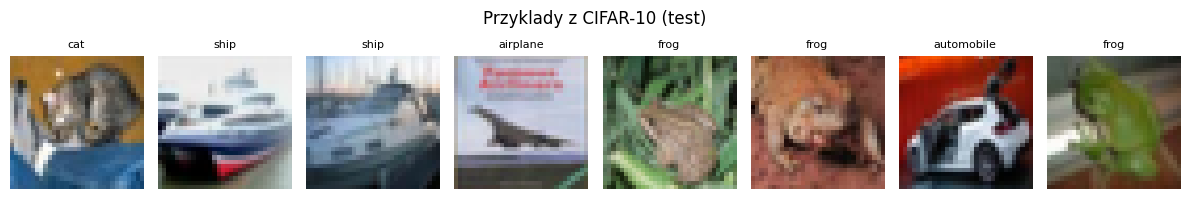

In [3]:
DATA_DIR = Path("./data")


def compute_dataset_stats(data_dir: Path):
    """Wylicza srednia i odchylenie standardowe pikseli wprost ze zbioru treningowego."""
    raw_train_ds = datasets.CIFAR10(str(data_dir), train=True, download=True)
    pixels = raw_train_ds.data.astype(np.float64) / 255.0
    mean = tuple(pixels.mean(axis=(0, 1, 2)).tolist())
    std = tuple(pixels.std(axis=(0, 1, 2)).tolist())
    return mean, std, raw_train_ds.data.shape, raw_train_ds.classes


def make_loaders(data_dir: Path, batch_size: int, num_workers: int = 2):
    """Tworzy obiekty DataLoader dla zbioru treningowego i testowego CIFAR-10."""
    mean, std, train_shape, classes = compute_dataset_stats(data_dir)
    train_tf = transforms.Compose([
        transforms.RandomCrop(train_shape[1], padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    test_tf = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    train_ds = datasets.CIFAR10(str(data_dir), train=True, download=True, transform=train_tf)
    test_ds = datasets.CIFAR10(str(data_dir), train=False, download=True, transform=test_tf)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, pin_memory=DEVICE.type == "cuda")
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                             num_workers=num_workers, pin_memory=DEVICE.type == "cuda")
    return train_loader, test_loader, classes, mean, std, train_shape

train_loader, test_loader, class_names, cifar_mean, cifar_std, train_shape = make_loaders(DATA_DIR, BATCH_SIZE)
in_channels = train_shape[-1]
num_classes = len(class_names)

print(f"Ksztalt zbioru treningowego: {train_shape} | Liczba klas: {num_classes}")
print(f"Klasy: {class_names}")
print(f"Wyliczona srednia RGB (train): {[round(m, 4) for m in cifar_mean]}")
print(f"Wyliczone odchylenie std RGB (train): {[round(s, 4) for s in cifar_std]}")
print(f"Train batches: {len(train_loader)} | Test batches: {len(test_loader)}\n")

model_a = ResNetCIFAR10(
    in_channels=in_channels,
    num_classes=num_classes,
    widths=STAGE_WIDTHS,
    blocks_per_stage=BLOCKS_PER_STAGE,
    shortcut_cls=IdentityPaddingShortcut,
)
model_b = ResNetCIFAR10(
    in_channels=in_channels,
    num_classes=num_classes,
    widths=STAGE_WIDTHS,
    blocks_per_stage=BLOCKS_PER_STAGE,
    shortcut_cls=ProjectionShortcut,
)

xb, yb = next(iter(test_loader))
print(f"Model Opcja A (Identity + Zero-Padding): {model_a.count_weighted_layers()} warstw | {model_a.count_parameters():,} parametrow")
print(f"Model Opcja B (Projekcja 1x1):           {model_b.count_weighted_layers()} warstw | {model_b.count_parameters():,} parametrow (+{model_b.count_parameters() - model_a.count_parameters():,} param.)")
print(f"Test forward na rzeczywistym batchu:     {tuple(xb.shape)} -> Opcja A: {tuple(model_a(xb).shape)}, Opcja B: {tuple(model_b(xb).shape)}")

# podglad kilku obrazow ze zbioru testowego (odwrocenie normalizacji)
inv_mean = torch.tensor(cifar_mean, dtype=xb.dtype).view(in_channels, 1, 1)
inv_std = torch.tensor(cifar_std, dtype=xb.dtype).view(in_channels, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    img = (xb[i] * inv_std + inv_mean).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(class_names[yb[i]], fontsize=8)
    ax.axis("off")
plt.suptitle("Przyklady z CIFAR-10 (test)")
plt.tight_layout()
plt.show()

## 5. Trening i ewaluacja obu wariantów (Opcja A oraz Opcja B)

Oba modele (`Opcja A` z bezparametrycznym uzupełnianiem zerami oraz `Opcja B` z projekcją $1 \times 1$) są trenowane i testowane w identycznych warunkach:

- **Funkcja straty (`nn.CrossEntropyLoss`):** mierzy błąd klasyfikacji za pomocą entropii krzyżowej wyliczanej z 10 logitów warstwy wyjściowej.
- **Optymalizator (`torch.optim.SGD` z `lr=0.1`, `momentum=0.9` i `weight_decay=1e-4`):** klasyczny stochastyczny spadek wzdłuż gradientu z pędem oraz regularyzacją L2.
- **Przycinanie gradientów (`clip_grad_norm_` z progiem `1.0`) oraz harmonogram `CosineAnnealingLR`:** harmonogram cosinusowy płynnie obniża współczynnik uczenia od `0.1` do `0` w trakcie 100 epok, zapewniając stabilną zbieżność.
- **Zapisywanie przebiegów:** historia treningu (`history.json`), podsumowanie (`summary.json`) oraz wagi najlepszego modelu (`best.pt`) są zapisywane osobno w katalogach `runs/option_A` oraz `runs/option_B`.

In [4]:
@torch.no_grad()
def evaluate(model, loader, device):
    """Oblicza srednia strate i dokladnosc klasyfikacji na zbiorze testowym."""
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        logits = model(x)
        total_loss += criterion(logits, y).item()
        correct += (logits.argmax(1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, 100.0 * correct / n


def train_one_epoch(model, loader, optimizer, device, grad_clip=1.0):
    """Przeprowadza jedna epoke treningu modelu i zwraca srednia strate oraz dokladnosc."""
    model.train()
    criterion = nn.CrossEntropyLoss()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in tqdm(loader, desc="train", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        if grad_clip > 0:
            nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, 100.0 * correct / n


RUNS_DIR = Path("./runs")
VARIANT_SPECS = {
    "A": ("Opcja A", IdentityPaddingShortcut, RUNS_DIR / "option_A"),
    "B": ("Opcja B", ProjectionShortcut, RUNS_DIR / "option_B"),
}

models = {}
histories = {}
best_accs = {}

for opt_key, (label, shortcut_cls, run_dir) in VARIANT_SPECS.items():
    torch.manual_seed(SEED)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)

    model = ResNetCIFAR10(
        in_channels=in_channels,
        num_classes=num_classes,
        widths=STAGE_WIDTHS,
        blocks_per_stage=BLOCKS_PER_STAGE,
        shortcut_cls=shortcut_cls,
    ).to(DEVICE)

    hist_path = run_dir / "history.json"
    ckpt_path = run_dir / "best.pt"

    if RETRAIN:
        run_dir.mkdir(parents=True, exist_ok=True)
        optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

        history = []
        best_acc = 0.0
        print(f"Start treningu ({label}) | params={model.count_parameters():,} | epochs={EPOCHS}")

        for epoch in range(1, EPOCHS + 1):
            t0 = time.time()
            train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, DEVICE)
            test_loss, test_acc = evaluate(model, test_loader, DEVICE)
            scheduler.step()
            row = {
                "epoch": epoch,
                "train_loss": train_loss,
                "train_acc": train_acc,
                "test_loss": test_loss,
                "test_acc": test_acc,
                "lr": optimizer.param_groups[0]["lr"],
                "seconds": time.time() - t0,
            }
            history.append(row)
            print(
                f"Epoch {epoch:03d}/{EPOCHS} | "
                f"train {train_loss:.4f}/{train_acc:.2f}% | "
                f"test {test_loss:.4f}/{test_acc:.2f}% | "
                f"lr {row['lr']:.4g} | {row['seconds']:.1f}s"
            )
            if train_loss != train_loss:
                print("NaN — stop")
                break
            if test_acc > best_acc:
                best_acc = test_acc
                torch.save(
                    {"model": model.state_dict(), "test_acc": test_acc, "epoch": epoch},
                    ckpt_path,
                )
            with open(hist_path, "w") as f:
                json.dump(history, f, indent=2)

        ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model"])
        print(f"Best test accuracy ({label}): {best_acc:.2f}% (epoch={ckpt.get('epoch')})\n")
        with open(run_dir / "summary.json", "w") as f:
            json.dump(
                {
                    "best_test_acc": best_acc,
                    "widths": list(STAGE_WIDTHS),
                    "blocks_per_stage": list(BLOCKS_PER_STAGE),
                    "shortcut_option": opt_key,
                    "params": model.count_parameters(),
                },
                f,
                indent=2,
            )
    else:
        if not (hist_path.is_file() and ckpt_path.is_file()):
            raise FileNotFoundError(
                f"Brak zapisanego przebiegu treningu w {run_dir}. Ustaw RETRAIN = True i uruchom trening."
            )
        with open(hist_path) as f:
            history = json.load(f)
        ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model"])
        best_acc = max(r["test_acc"] for r in history)
        print(f"Start treningu ({label}) | params={model.count_parameters():,} | epochs={len(history)}")
        for r in history:
            print(
                f"Epoch {r['epoch']:03d}/{len(history)} | "
                f"train {r['train_loss']:.4f}/{r['train_acc']:.2f}% | "
                f"test {r['test_loss']:.4f}/{r['test_acc']:.2f}% | "
                f"lr {r['lr']:.4g} | {r['seconds']:.1f}s"
            )
        print(f"Best test accuracy ({label}): {best_acc:.2f}% (epoch={ckpt.get('epoch')})\n")

    models[opt_key] = model
    histories[opt_key] = history
    best_accs[opt_key] = best_acc

Start treningu (Opcja A) | params=853,018 | epochs=100
Epoch 001/100 | train 1.7161/36.89% | test 1.5171/46.60% | lr 0.09998 | 5.9s
Epoch 002/100 | train 1.1713/57.83% | test 1.1678/59.59% | lr 0.0999 | 5.5s
Epoch 003/100 | train 0.8983/68.20% | test 0.9307/68.40% | lr 0.09978 | 5.4s
Epoch 004/100 | train 0.7583/73.65% | test 0.8480/71.52% | lr 0.09961 | 5.4s
Epoch 005/100 | train 0.6524/77.24% | test 0.7008/77.02% | lr 0.09938 | 5.4s
Epoch 006/100 | train 0.5936/79.44% | test 0.6357/78.03% | lr 0.09911 | 5.4s
Epoch 007/100 | train 0.5394/81.26% | test 0.6947/78.07% | lr 0.0988 | 5.4s
Epoch 008/100 | train 0.4960/82.80% | test 0.6370/78.78% | lr 0.09843 | 5.4s
Epoch 009/100 | train 0.4642/83.92% | test 0.5692/81.19% | lr 0.09801 | 5.4s
Epoch 010/100 | train 0.4409/84.95% | test 0.5325/82.44% | lr 0.09755 | 5.4s
Epoch 011/100 | train 0.4186/85.53% | test 0.5264/82.50% | lr 0.09704 | 5.5s
Epoch 012/100 | train 0.4018/86.18% | test 0.5542/81.84% | lr 0.09649 | 5.4s
Epoch 013/100 | train 0

Start treningu (Opcja B) | params=855,770 | epochs=100
Epoch 001/100 | train 1.7810/33.66% | test 1.3860/49.56% | lr 0.09998 | 5.6s
Epoch 002/100 | train 1.1815/57.33% | test 1.6071/47.47% | lr 0.0999 | 5.4s
Epoch 003/100 | train 0.9281/67.12% | test 1.0346/65.27% | lr 0.09978 | 5.6s
Epoch 004/100 | train 0.7735/73.00% | test 0.9748/68.77% | lr 0.09961 | 5.6s
Epoch 005/100 | train 0.6766/76.68% | test 0.7112/75.20% | lr 0.09938 | 5.5s
Epoch 006/100 | train 0.6136/78.74% | test 0.6450/77.95% | lr 0.09911 | 6.0s
Epoch 007/100 | train 0.5576/80.75% | test 0.8172/73.51% | lr 0.0988 | 5.5s
Epoch 008/100 | train 0.5217/82.01% | test 0.5690/80.43% | lr 0.09843 | 5.7s
Epoch 009/100 | train 0.4816/83.31% | test 0.5690/80.61% | lr 0.09801 | 5.5s
Epoch 010/100 | train 0.4565/84.18% | test 0.6829/78.74% | lr 0.09755 | 5.5s
Epoch 011/100 | train 0.4342/84.89% | test 0.5076/82.98% | lr 0.09704 | 5.6s
Epoch 012/100 | train 0.4050/85.92% | test 0.7206/76.72% | lr 0.09649 | 5.5s
Epoch 013/100 | train 0

## 6. Porównanie Opcji A i Opcji B oraz krzywe uczenia

Poniższa komórka wizualizuje przebieg funkcji kosztu (**Cross-entropy loss**) oraz dokładności klasyfikacji (**Accuracy [%]**) w kolejnych epokach dla obu wariantów połączeń skrótowych (**Opcja A** vs **Opcja B**), a także wykonuje bezpośrednią ewaluację obu wczytanych modeli na zbiorze testowym `test_loader`.

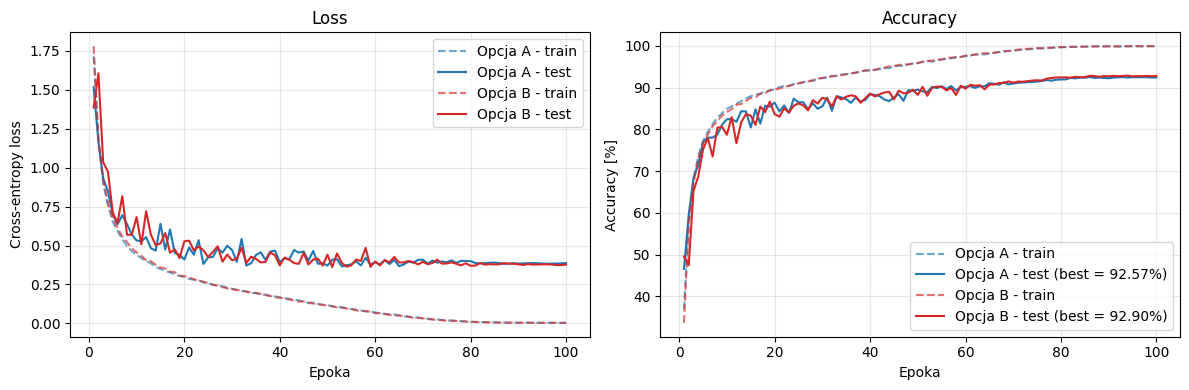

=== Opcja A ===
Architektura modelu:     widths=(16, 32, 64), blocks=(9, 9, 9) (56 warstw, 853,018 parametrow)
Najlepsze test accuracy: 92.57% (w historii treningu)
Ostatnie test accuracy:  92.46%
Test accuracy z modelu:  92.57% (loss = 0.3866)



=== Opcja B ===
Architektura modelu:     widths=(16, 32, 64), blocks=(9, 9, 9) (56 warstw, 855,770 parametrow)
Najlepsze test accuracy: 92.90% (w historii treningu)
Ostatnie test accuracy:  92.82%
Test accuracy z modelu:  92.90% (loss = 0.3779)



In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

colors = {"A": "#1f77b4", "B": "#d62728"}

for opt_key, (label, _, _) in VARIANT_SPECS.items():
    hist = histories[opt_key]
    epochs = [r["epoch"] for r in hist]
    train_acc = [r["train_acc"] for r in hist]
    test_acc = [r["test_acc"] for r in hist]
    train_loss = [r["train_loss"] for r in hist]
    test_loss = [r["test_loss"] for r in hist]

    axes[0].plot(epochs, train_loss, color=colors[opt_key], ls="--", alpha=0.65, label=f"{label} - train")
    axes[0].plot(epochs, test_loss, color=colors[opt_key], label=f"{label} - test")

    axes[1].plot(epochs, train_acc, color=colors[opt_key], ls="--", alpha=0.65, label=f"{label} - train")
    axes[1].plot(epochs, test_acc, color=colors[opt_key], label=f"{label} - test (best = {best_accs[opt_key]:.2f}%)")

axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Accuracy [%]")
axes[1].set_title("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(RUNS_DIR / "curves_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

for opt_key, (label, _, _) in VARIANT_SPECS.items():
    m = models[opt_key]
    hist = histories[opt_key]
    eval_loss, eval_acc = evaluate(m, test_loader, DEVICE)
    print(f"=== {label} ===")
    print(f"Architektura modelu:     widths={STAGE_WIDTHS}, blocks={BLOCKS_PER_STAGE} ({m.count_weighted_layers()} warstw, {m.count_parameters():,} parametrow)")
    print(f"Najlepsze test accuracy: {best_accs[opt_key]:.2f}% (w historii treningu)")
    print(f"Ostatnie test accuracy:  {hist[-1]['test_acc']:.2f}%")
    print(f"Test accuracy z modelu:  {eval_acc:.2f}% (loss = {eval_loss:.4f})\n")